In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.neural_network import BernoulliRBM
from sklearn.model_selection import train_test_split

from __future__ import annotations
from stock_sim import stock

import math
import random
from dataclasses import dataclass
from typing import List, Tuple, Callable

import kagglehub

path = kagglehub.dataset_download("jacksoncrow/stock-market-dataset")

print("Path to dataset files:", path)

/usr/local/python/3.12.1/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /home/codespace/.cache/kagglehub/datasets/jacksoncrow/stock-market-dataset/versions/2


In [2]:
df_metadata = pd.read_csv(path+"/symbols_valid_meta.csv")
Stocks = os.listdir(path+"/stocks")
train_set = [pd.read_csv(path+"/stocks/"+i) for i in Stocks[0:14]]
test_set = [pd.read_csv(path+"/stocks/"+i) for i in Stocks[15:19]]

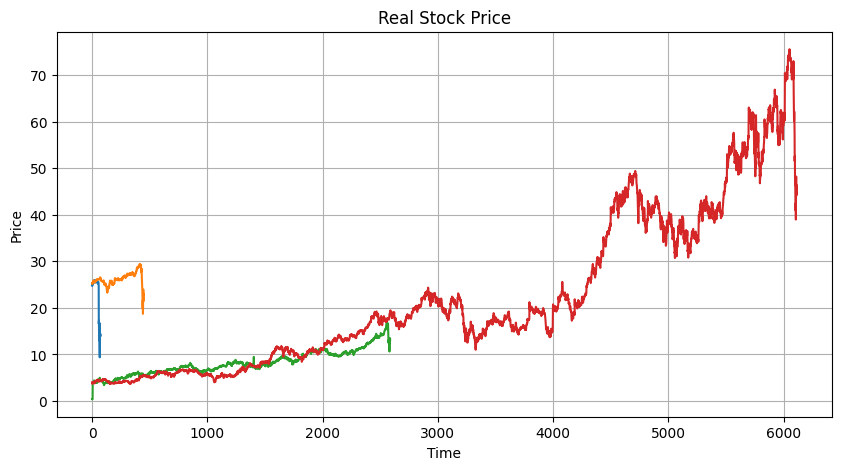

In [3]:
plt.figure(figsize=(10,5))
for df in test_set:
    plt.plot(df["High"])

plt.title("Real Stock Price")
plt.xlabel("Time")
plt.ylabel("Price")
plt.grid(True)
plt.show()

In [4]:
def build_inputs(price_series, t, last_buy, last_sell, portfolio_value):
    inputs =  {
        "normalized_current_price": price_series[t]/price_series[0],
        "normalized_previous_price": [price_series[t-1]/price_series[0] if t > 0 else 1][0],
        "volatility": np.std(np.log(np.array([price_series[j]/price_series[j-1] if t > 0 else 1 for j in range(1,t)]))),
        "mean": np.mean([price_series[j] for j in range(0,t)]),
        "average_gradient_10": (price_series[t]-price_series[t-10])/10,
        "average_gradient_100": (price_series[t]-price_series[t-100])/100,
        "average_gradient_all": [(price_series[t]-price_series[0])/t if t > 0 else 0][0],
        "time_since_last_buy": t - last_buy,
        "time_since_last_sell": t - last_sell,
        "current_portfolio_value": portfolio_value
    }
    return list(inputs.values())

def interpret_outputs(o_buy, o_sell, o_hold):
    return np.argmax([o_buy,o_sell,o_hold])

In [ ]:
import neat
import os

# -----------------------------------------
# Your environment simulation
# -----------------------------------------
def run_simulation(net, balance = 1000.0, max_steps=300):
    """
    Runs the agent for a fixed number of steps.
    Returns the accumulated score (fitness).
    """
    fitnesses = []

    for price_series in train_set:
        shares = 0
        last_buy = 0
        last_sell = 0
        portfolio_value = balance
        for t in range(0, min(1024,len(price_series))):
            inputs = build_inputs(price_series["High"].tolist(), t, last_buy=last_buy, last_sell=last_sell, portfolio_value=portfolio_value)
            o_buy, o_sell, o_hold = net.activate(inputs)

            action = interpret_outputs(o_buy, o_sell, o_hold)
            price = price_series["High"][t]

            if action == 0 and balance >= price:
                shares += 1
                balance -= price
                last_buy = t

            elif action == 1 and shares > 0:
                balance += price
                shares -= 1
                last_sell = t

            # reward = portfolio value
            portfolio_value = balance + shares * price

        fitnesses.append(portfolio_value)
    #print(fitnesses), print(np.mean(fitnesses))
    return sum(fitnesses)/len(train_set)

# -----------------------------------------
# NEAT evaluation functions
# -----------------------------------------
def eval_genome(genome, config):
    net = neat.nn.FeedForwardNetwork.create(genome, config)
    fitness = run_simulation(net)
    #print(fitness)
    return fitness


def eval_genomes(genomes, config):
    for genome_id, genome in genomes:
        genome.fitness = eval_genome(genome, config)
    #print(f"Best fitness: {max([genome.fitness for genome_id, genome in genomes])}")

# -----------------------------------------
# Running NEAT
# -----------------------------------------
def run():
    config_path = "config-feedforward.ini"

    config = neat.Config(
        neat.DefaultGenome,
        neat.DefaultReproduction,
        neat.DefaultSpeciesSet,
        neat.DefaultStagnation,
        config_path,
    )

    population = neat.Population(config)

    population.add_reporter(neat.StdOutReporter(True))
    stats = neat.StatisticsReporter()
    population.add_reporter(stats)

    winner = population.run(eval_genomes, n=100)

    print("Best genome:", winner)

    return winner


winner = run()


 ****** Running generation 0 ****** 



/usr/local/python/3.12.1/lib/python3.12/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/python/3.12.1/lib/python3.12/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/python/3.12.1/lib/python3.12/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/python/3.12.1/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/python/3.12.1/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Population's average fitness: 684.48636 stdev: 439.59288
Best fitness: 1000.00000 - size: (3, 0) - species 1 - id 1
Average adjusted fitness: 0.660
Mean genetic distance 1.366, standard deviation 0.585
Population of 150 members in 1 species (after reproduction):
   ID   age  size   fitness   adj fit  stag
  ====  ===  ====  =========  =======  ====
     1    0   150   1000.000    0.660     0
Total extinctions: 0
Generation time: 706.221 sec

 ****** Running generation 1 ****** 

Population's average fitness: 804.53773 stdev: 365.56132
Best fitness: 1000.00000 - size: (3, 0) - species 1 - id 150
Average adjusted fitness: 0.790
Mean genetic distance 1.578, standard deviation 0.527
Population of 150 members in 1 species (after reproduction):
   ID   age  size   fitness   adj fit  stag
  ====  ===  ====  =========  =======  ====
     1    1   150   1000.000    0.790     1
Total extinctions: 0
Generation time: 596.961 sec (651.591 average)

 ****** Running generation 2 ****** 

Population's

In [ ]:
config_path = "config-feedforward.ini"

config = neat.Config(
        neat.DefaultGenome,
        neat.DefaultReproduction,
        neat.DefaultSpeciesSet,
        neat.DefaultStagnation,
        config_path,
    )

net = neat.nn.FeedForwardNetwork.create(winner, config)

price_series = train_set[1]

shares = 0
last_buy = 0
last_sell = 0
portfolio_value = 1000
balance = 1000
outputs = []
fitnesses = []
for t in range(1, len(price_series)):
    inputs = build_inputs(price_series["High"].tolist(), t,  last_buy=last_buy, last_sell=last_sell, portfolio_value=portfolio_value)
    o_buy, o_sell, o_hold = net.activate(inputs)

    action = interpret_outputs(o_buy, o_sell, o_hold)
    outputs.append(action)
    price = price_series["High"].tolist()[t]

    if action == "BUY" and balance >= price:
        shares += 1
        balance -= price
        last_buy = t

    elif action == "SELL" and shares > 0:
        balance += price
        shares -= 1
        last_sell = t

    fitnesses.append(balance + shares * price)
    # reward = portfolio value
    portfolio_value = balance + shares * price

print(portfolio_value)

In [11]:
def test_simulation(net, idx, balance = 1000.0, max_steps=300):
    """
    Runs the agent for a fixed number of steps.
    Returns the accumulated score (fitness).
    """
    fitnesses = []
    outputs = []

    for price_series in [train_set[idx]]:
        shares = 0
        last_buy = 0
        last_sell = 0
        portfolio_value = balance
        for t in range(0, len(price_series)):
            inputs = build_inputs(price_series["High"].tolist(), t, last_buy=last_buy, last_sell=last_sell, portfolio_value=portfolio_value)
            o_buy, o_sell, o_hold = net.activate(inputs)

            action = interpret_outputs(o_buy, o_sell, o_hold)
            price = price_series["High"][t]
            if action == 0 and balance >= price:
                shares += 1
                balance -= price
                last_buy = t

            elif action == 1 and shares > 0:
                balance += price
                shares -= 1
                last_sell = t

            # reward = portfolio value
            portfolio_value = balance + shares * price
            #print(balance, shares, price)
            fitnesses.append(portfolio_value)
            outputs.append(action)
    #print(fitnesses), print(np.mean(fitnesses))
    return fitnesses, outputs

def test_genome(genome,config,idx):
    net = neat.nn.FeedForwardNetwork.create(genome, config)
    fitnesses, outputs = test_simulation(net,idx)
    return fitnesses, outputs

In [ ]:
config_path = "config-feedforward.ini"

config = neat.Config(
        neat.DefaultGenome,
        neat.DefaultReproduction,
        neat.DefaultSpeciesSet,
        neat.DefaultStagnation,
        config_path,
    )

print("Train Set")
print(f"Fitness: {(test_genome(winner,config,4)[0])[-1]}")


In [ ]:
plt.figure(figsize=(10,5))
idx = 5
price_list = train_set[idx]
fitnesses, outputs = test_genome(winner,config,idx)
colours = {"0":"green", "1":"red", "2":"blue"}
print(len(price_list),len(outputs))
fig, ax1 = plt.subplots(figsize=(12, 6))
for t in range(len(price_list["High"].tolist())-1):
    ax1.plot([t,t+1],[price_list["High"][t],price_list["High"][t+1]],color=colours[str(int(outputs[t]))],linewidth=2)
ax1.set_xlabel("Time")
ax1.set_ylabel("Price",color="black")
ax1.tick_params(axis="y",labelcolor="black")

ax2 = ax1.twinx()

ax2.plot(fitnesses,color="purple")
ax2.set_ylabel("Portfolio Value",color="purple")
ax2.tick_params(axis="y", labelcolor="purple")

plt.title("Simulated Stock Price and Outputs")
plt.tight_layout()
plt.grid(True)
plt.show()